We'll now test Colgate-Palmolive (CL) and General Mills (GIS) using the relationship estimated during 2018–2021, with 2022 onward reserved for out-of-sample evaluation.

In [3]:
%pip install yfinance

import yfinance as yf
import numpy as np
import pandas as pd

prices = yf.download(
    ["CL", "GIS"],
    start="2018-01-01",
    end="2026-10-07",
    auto_adjust=True,
    progress=False,
    multi_level_index=False
)["Close"]

prices = prices[["CL", "GIS"]].dropna()

log_prices = np.log(prices)

formation = log_prices.loc[:"2021-12-31"]
test_prices = prices.loc["2022-01-01":]

beta, intercept = np.polyfit(
    formation["GIS"].to_numpy(),
    formation["CL"].to_numpy(),
    1
)

print("Columns:", prices.columns.tolist())
print(f"Formation beta: {beta:.4f}")
print(f"Formation observations: {len(formation)}")
print(f"Test observations: {len(test_prices)}")

Note: you may need to restart the kernel to use updated packages.
Columns: ['CL', 'GIS']
Formation beta: 0.5884
Formation observations: 1008
Test observations: 1194


In [7]:
# Spread for the formation period and the test period
spread = (
    log_prices["CL"]
    - intercept
    - beta * log_prices["GIS"]
)

rolling_mean = spread.rolling(60).mean()
rolling_std = spread.rolling(60).std()

zscore = (spread - rolling_mean) / rolling_std

# Only evaluate signals in the out-of-sample period
test_z = zscore.reindex(test_prices.index)

position = pd.Series(
    0.0, index=test_prices.index, name="position"
)

current_position = 0.0

for date, z in test_z.items():
    if pd.isna(z):
        position.loc[date] = current_position
        continue

    if current_position == 0:
        if z < -2:
            current_position = 1.0  # Long spread
        elif z > 2:
            current_position = -1.0  # Short spread

    elif current_position == 1 and z >= -0.5:
        current_position = 0.0

    elif current_position == -1 and z <= 0.5:
        current_position = 0.0

    position.loc[date] = current_position

print(position.value_counts())

position
 0.0    583
-1.0    382
 1.0    229
Name: count, dtype: int64


In [8]:
returns = test_prices.pct_change()

# Approximate daily return of the hedged spread portfolio
spread_returns = (
    returns["CL"] - beta * returns["GIS"]
) / (1 + abs(beta))

strategy_returns = (
    position.shift(1).fillna(0) * spread_returns
).dropna()

equity = (1 + strategy_returns).cumprod()
drawdown = equity / equity.cummax() - 1

total_return = equity.iloc[-1] - 1

annualized_sharpe = (
    np.sqrt(252)
    * strategy_returns.mean()
    / strategy_returns.std()
    if strategy_returns.std() > 0
    else np.nan
)

annualized_volatility = strategy_returns.std() * np.sqrt(252)

print(f"Out-of-sample total return: {total_return:.2%}")
print(f"Annualized Sharpe: {annualized_sharpe:.2f}")
print(f"Annualized volatility: {annualized_volatility:.2%}")
print(f"Maximum drawdown: {drawdown.min():.2%}")
print(f"Entry signals: {((position != 0) & (position.shift(1).fillna(0) == 0)).sum()}")

Out-of-sample total return: -6.03%
Annualized Sharpe: -0.13
Annualized volatility: 7.63%
Maximum drawdown: -15.84%
Entry signals: 22


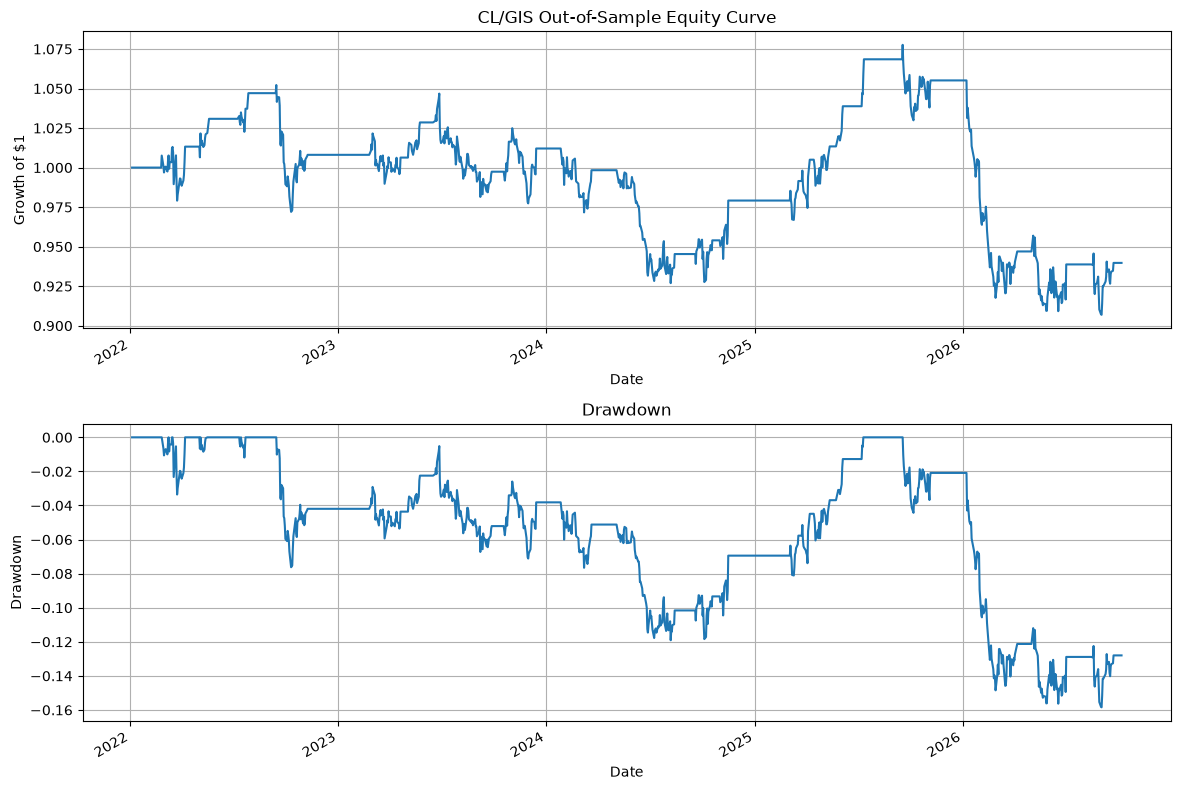

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

equity.plot(ax=axes[0], title="CL/GIS Out-of-Sample Equity Curve")
axes[0].set_ylabel("Growth of $1")
axes[0].grid(True)

drawdown.plot(ax=axes[1], title="Drawdown")
axes[1].set_ylabel("Drawdown")
axes[1].grid(True)

plt.tight_layout()
plt.show()

The performance is weak. Let's figure it out why. 

In [10]:
yearly = []

for year, r in strategy_returns.groupby(strategy_returns.index.year):
    equity_year = (1 + r).cumprod()
    drawdown_year = equity_year / equity_year.cummax() - 1

    sharpe = (
        np.sqrt(252) * r.mean() / r.std()
        if r.std() > 0 else np.nan
    )

    yearly.append({
        "year": year,
        "observations": len(r),
        "total_return": (1 + r).prod() - 1,
        "annualized_sharpe": sharpe,
        "max_drawdown": drawdown_year.min()
    })

yearly_df = pd.DataFrame(yearly)

print(yearly_df.to_string(index=False))

 year  observations  total_return  annualized_sharpe  max_drawdown
 2022           250      0.008068           0.153888     -0.076235
 2023           250      0.003969           0.092390     -0.066327
 2024           252     -0.032523          -0.409423     -0.084135
 2025           250      0.077593           1.222916     -0.044307
 2026           191     -0.109378          -1.350756     -0.140492


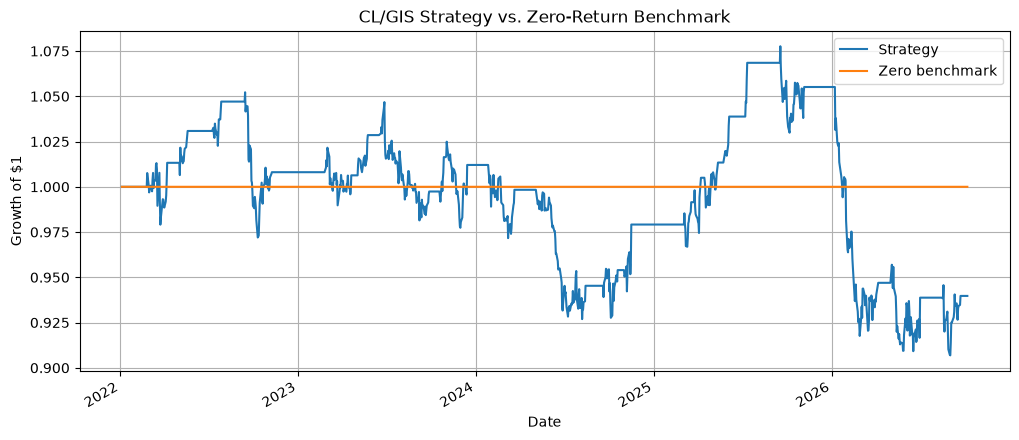

In [11]:
comparison = pd.DataFrame({
    "Strategy": strategy_returns,
    "Zero benchmark": pd.Series(
        0.0, index=strategy_returns.index
    )
})

equity_comparison = (1 + comparison).cumprod()

equity_comparison.plot(
    figsize=(12, 5),
    title="CL/GIS Strategy vs. Zero-Return Benchmark"
)

plt.ylabel("Growth of $1")
plt.grid(True)
plt.show()

In [12]:
from statsmodels.tsa.stattools import adfuller

test_spread = spread.reindex(test_prices.index).dropna()

adf_stat, adf_pvalue, *_ = adfuller(
    test_spread,
    regression="c",
    autolag="AIC"
)

print(f"Test-period spread ADF statistic: {adf_stat:.4f}")
print(f"Test-period spread ADF p-value: {adf_pvalue:.4f}")

Test-period spread ADF statistic: 0.3782
Test-period spread ADF p-value: 0.9807


/tmp/ipykernel_4525/277272985.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_pvalue, *_ = adfuller(


The strategy performed well in 2025 but gave back those gains and more during 2026. That is a warning against judging a pairs-trading strategy by its best year alone.

Also, testing every possible pair of stocks may be a bad idea. Next, we will automate the screening process until we find a promising pair. 